In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm 
import scipy.stats as stats
import seaborn as sns

In [22]:
data = pd.read_csv('./Salary_dataset.csv')

data_train = data.sample(frac= 0.8, random_state = 49)
data_test = data.drop(data_train.index)

In [23]:
data_train.head()

,Unnamed: 0,YearsExperience,Salary
14,14,4.6,61112.0
9,9,3.8,57190.0
16,16,5.2,66030.0
24,24,8.8,109432.0
28,28,10.4,122392.0


<Axes: >

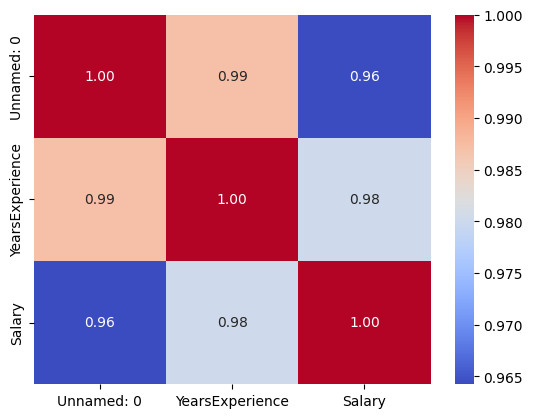

In [24]:
corr = data_train.corr()

sns.heatmap(corr, cmap = 'coolwarm', annot = True, fmt = '.2f')

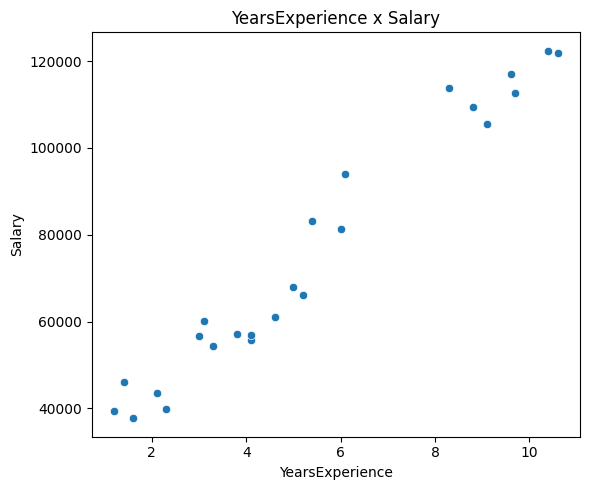

In [25]:
x_cols = ['YearsExperience']
y_col = 'Salary'

fig, axes = plt.subplots(
    1, 
    len(x_cols), 
    figsize=(6 * len(x_cols), 5), 
    squeeze=False
)

axes = axes.flatten()

for i, x_col in enumerate(x_cols):
    sns.scatterplot(
        x = x_col,
        y = y_col,
        data = data_train,
        ax = axes[i]
    )
    axes[i].set_title(f'{x_col} x {y_col}')

plt.tight_layout()
plt.show()

In [26]:
formula = 'Salary ~ YearsExperience'
model = sm.ols(formula = formula, data = data_train)

model = model.fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.961
Model:                            OLS   Adj. R-squared:                  0.959
Method:                 Least Squares   F-statistic:                     538.4
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           5.85e-17
Time:                        10:18:55   Log-Likelihood:                -241.54
No. Observations:                  24   AIC:                             487.1
Df Residuals:                      22   BIC:                             489.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        2.459e+04   2494.095      9.858      0.000    1.94e+04    2.98e+04
YearsExperience  9425.4008    406.225     23.202      0.000    8582.942    1.03e+04
==============================================================================
Omnibus:                        2.034   Durbin-Watson:                   2.090
Prob(Omnibus):                  0.362   Jarque-Bera (JB):                1.750
Skew:                           0.561   Prob(JB):                        0.417
Kurtosis:                       2.298   Cond. No.                         12.9
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

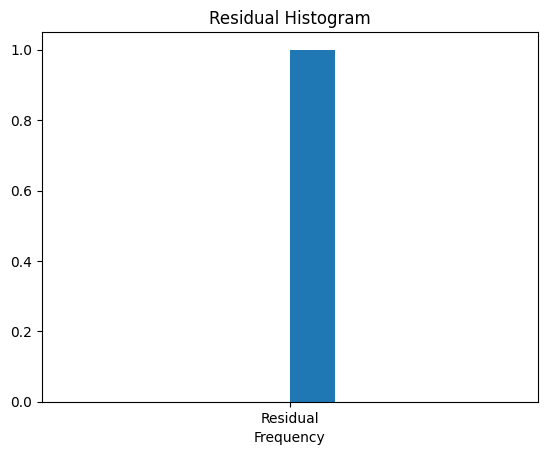

In [27]:
residual = model.resid

plt.hist('Residual')
plt.xlabel('Frequency')
plt.title('Residual Histogram')

plt.show()

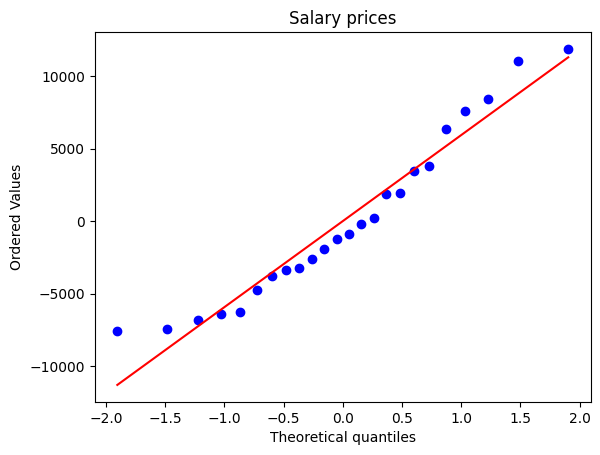

In [28]:
stats.probplot(residual, dist = 'norm', plot = plt)
plt.title('Salary prices')
plt.show()

In [29]:
shapiro_test = stats.shapiro(residual)
print(f'Shapiro-Wilker: \nW => {shapiro_test[0]} \nP => {shapiro_test[1]}')

Shapiro-Wilker: 
W => 0.9371979320117311 
P => 0.1412402646550454


In [30]:
prediction = model.predict(data_test)
real = data_test['Salary']

medium_error = np.mean(np.abs(real - prediction))
percent_error = np.mean(np.abs(real - prediction) / real) * 100
rmse_log = np.sqrt(np.mean((np.log(prediction) - np.log(real)) ** 2))
r2 = 1 - np.sum((real - prediction) **2) / np.sum((real - real.mean()) **2)

print(f'Erro médio: {medium_error}')
print(f'Erro médio percentual: {percent_error:.2f}%')
print(f'RMSE (log): {rmse_log:.4f}%')
print(f'R² no teste: {r2:.3f}')

comparation = pd.DataFrame({
    'Real': data_test['Salary'],
    'Prediction': prediction,
    'Diference': data_test['Salary'] - prediction,
    'Deference(%)': (data_test['Salary'] - prediction) / data_test['Salary'] * 100
})

comparation.head(10)

Erro médio: 4339.111705339231
Erro médio percentual: 6.17%
RMSE (log): 0.0813%
R² no teste: 0.915


,Real,Prediction,Diference,Deference(%)
8,64446.0,55689.879950,8756.120050,13.586755
10,63219.0,62287.660531,931.339469,1.473196
13,57082.0,64172.740698,-7090.740698,-12.422026
20,91739.0,89621.322940,2117.677060,2.308372
21,98274.0,92448.943190,5825.056810,5.927363
22,101303.0,99989.263854,1313.736146,1.296838
